# 01 — Exploratory Data Analysis: Telco Customer Churn

**Phase 2** of the roadmap (see `CONTINUITY.md`). Goal: understand who churns before building any model.

Covers tasks 2.1–2.4: churn rate by key segments, distributions of the numeric features, a correlation heatmap, and written business insights. Every figure is also saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.load_data import load_raw

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: thin marks, quiet axes, one fixed colour per meaning
STAYED, CHURNED = "#2a78d6", "#eb6834"   # categorical slots 1 and 2 (CVD-checked pair)
INK, QUIET, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": QUIET, "axes.titlecolor": INK,
    "xtick.color": QUIET, "ytick.color": QUIET,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

df = load_raw()
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # 11 blanks -> NaN (tenure 0)
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0–12 mo", "13–24 mo", "25–48 mo", "49–72 mo"])
OVERALL = df["churn_flag"].mean()
print(f"{len(df):,} customers | overall churn rate {OVERALL:.1%}")

7,043 customers | overall churn rate 26.5%


## Overall class balance
About 1 in 4 customers churned. A model that always predicts "No churn" would already score ~73% accuracy — so accuracy alone is a misleading metric here.

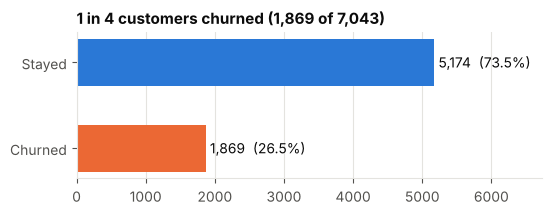

In [2]:
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(6, 1.9))
ax.barh(["Stayed", "Churned"], counts.values, color=[STAYED, CHURNED], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 60, i, f"{v:,}  ({v / len(df):.1%})", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title("1 in 4 customers churned (1,869 of 7,043)", loc="left")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
fig.savefig(FIG_DIR / "01_class_balance.png")
plt.show()

## 2.1 Churn rate by Contract, tenure, InternetService and PaymentMethod
Each bar is the share of customers in that group who churned. The dashed line is the overall rate (26.5%), so bars to its right are above-average risk.

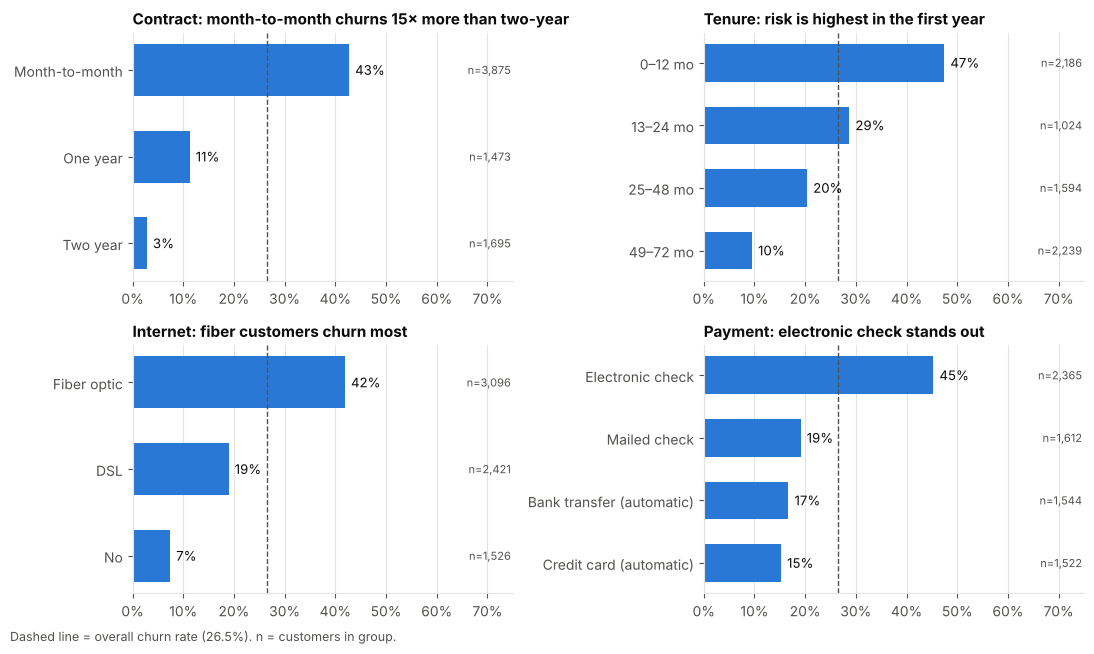

In [3]:
def churn_rate_bars(ax, col, title, order=None):
    rates = df.groupby(col, observed=True)["churn_flag"].agg(["mean", "size"])
    rates = rates.reindex(order) if order else rates.sort_values("mean")
    y = np.arange(len(rates))
    ax.barh(y, rates["mean"], color=STAYED, height=0.6)
    ax.set_yticks(y, [str(i) for i in rates.index])
    for yi, (m, n) in zip(y, rates.values):
        ax.text(m + 0.012, yi, f"{m:.0%}", va="center", color=INK, fontsize=9.5)
        ax.text(0.995, yi, f"n={int(n):,}", va="center", ha="right", color=QUIET, fontsize=8,
                transform=ax.get_yaxis_transform())
    ax.axvline(OVERALL, color=QUIET, linestyle="--", linewidth=1)
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
churn_rate_bars(axes[0, 0], "Contract", "Contract: month-to-month churns 15× more than two-year",
                order=["Two year", "One year", "Month-to-month"])
churn_rate_bars(axes[0, 1], "tenure_group", "Tenure: risk is highest in the first year",
                order=["49–72 mo", "25–48 mo", "13–24 mo", "0–12 mo"])
churn_rate_bars(axes[1, 0], "InternetService", "Internet: fiber customers churn most")
churn_rate_bars(axes[1, 1], "PaymentMethod", "Payment: electronic check stands out")
fig.text(0.01, -0.01, "Dashed line = overall churn rate (26.5%). n = customers in group.", color=QUIET, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_churn_rate_key_segments.png")
plt.show()

### Supporting segments
Add-on services, demographics and billing. Gender is shown as a control: it makes almost no difference.

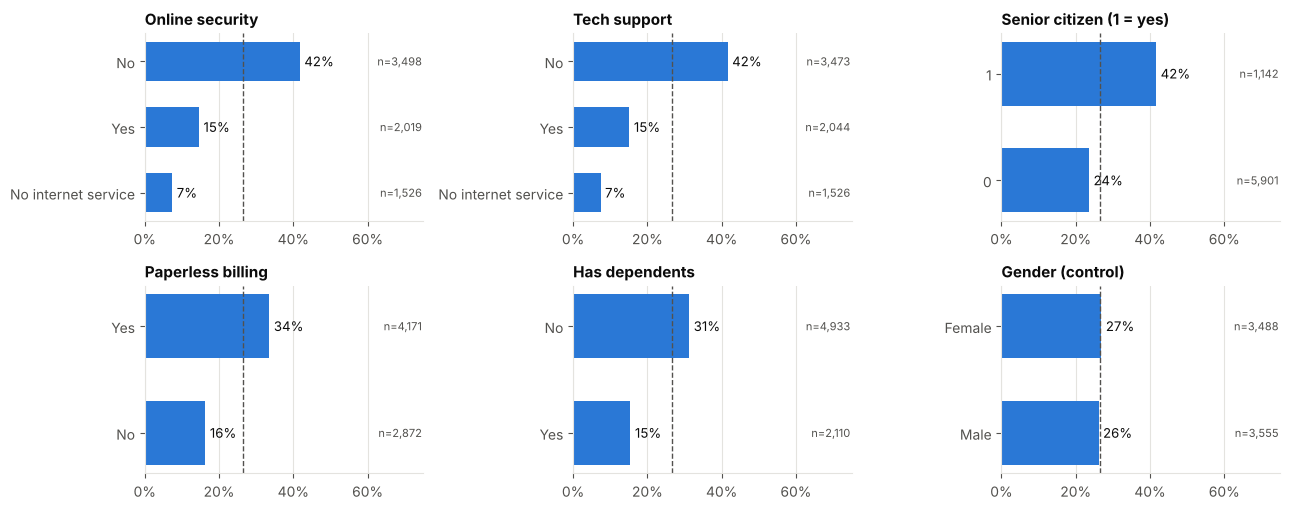

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.2))
for ax, (col, title) in zip(axes.flat, [
    ("OnlineSecurity", "Online security"), ("TechSupport", "Tech support"),
    ("SeniorCitizen", "Senior citizen (1 = yes)"), ("PaperlessBilling", "Paperless billing"),
    ("Dependents", "Has dependents"), ("gender", "Gender (control)")]):
    churn_rate_bars(ax, col, title)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_churn_rate_supporting_segments.png")
plt.show()

InternetService  Fiber optic    DSL     No
Contract                                  
Month-to-month         0.546  0.322  0.189
One year               0.193  0.093  0.025
Two year               0.072  0.019  0.008


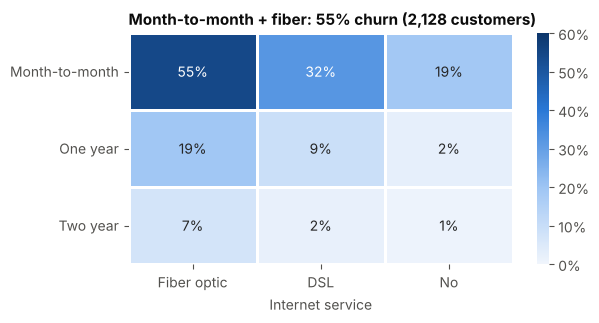

In [5]:
# Where the risk concentrates: contract x internet service
pivot = df.pivot_table(index="Contract", columns="InternetService", values="churn_flag", aggfunc="mean")
pivot = pivot.reindex(["Month-to-month", "One year", "Two year"])[["Fiber optic", "DSL", "No"]]
seq = LinearSegmentedColormap.from_list("blue_seq", ["#f0f5fc", "#9ec5f4", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(6.2, 3))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap=seq, vmin=0, vmax=0.6, linewidths=2, linecolor="white",
            cbar_kws={"format": plt.FuncFormatter(lambda v, _: f"{v:.0%}")}, ax=ax)
ax.set_title("Month-to-month + fiber: 55% churn (2,128 customers)", loc="left")
ax.set_xlabel("Internet service"); ax.set_ylabel("")
fig.savefig(FIG_DIR / "04_contract_x_internet.png")
plt.show()
print(pivot.round(3))

## 2.2 Distributions of tenure, MonthlyCharges and TotalCharges by churn
Density curves put both groups on the same scale even though there are ~3× more stayers than churners.

       tenure  MonthlyCharges  TotalCharges_num
Churn                                          
No       38.0            64.4            1683.6
Yes      10.0            79.6             703.6


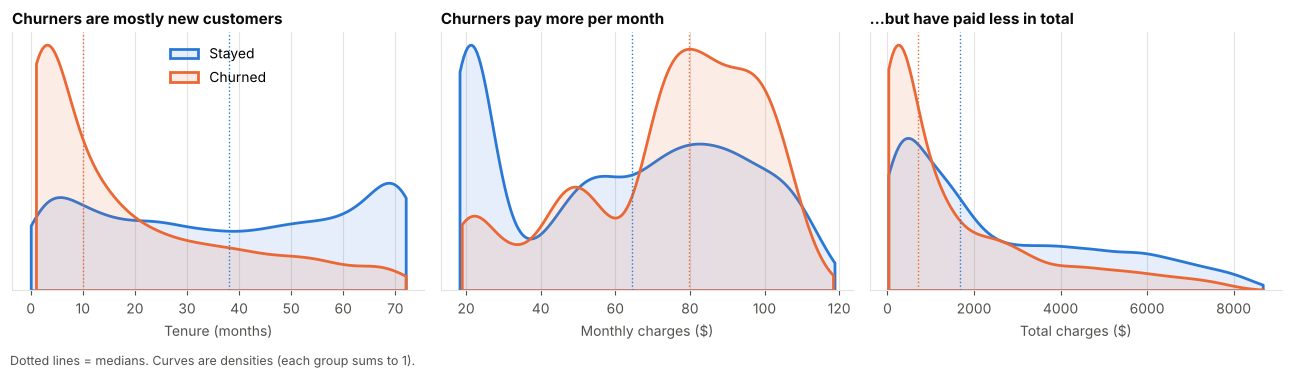

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, label) in zip(axes, [("tenure", "Tenure (months)"),
                                   ("MonthlyCharges", "Monthly charges ($)"),
                                   ("TotalCharges_num", "Total charges ($)")]):
    for value, color, name in [("No", STAYED, "Stayed"), ("Yes", CHURNED, "Churned")]:
        data = df.loc[df["Churn"] == value, col].dropna()
        sns.kdeplot(data, ax=ax, color=color, linewidth=2, fill=True, alpha=0.12, cut=0, label=name)
        ax.axvline(data.median(), color=color, linewidth=1, linestyle=":")
    ax.set_xlabel(label); ax.set_ylabel(""); ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].set_title("Churners are mostly new customers", loc="left")
axes[1].set_title("Churners pay more per month", loc="left")
axes[2].set_title("…but have paid less in total", loc="left")
axes[0].legend(loc="upper center")
fig.text(0.01, -0.03, "Dotted lines = medians. Curves are densities (each group sums to 1).", color=QUIET, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_numeric_distributions.png")
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges_num"]].median().round(1))

## 2.3 Correlation heatmap (numeric features + churn flag)

tenure           -0.35
TotalCharges     -0.20
SeniorCitizen     0.15
MonthlyCharges    0.19
Name: Churn (1=yes), dtype: float64


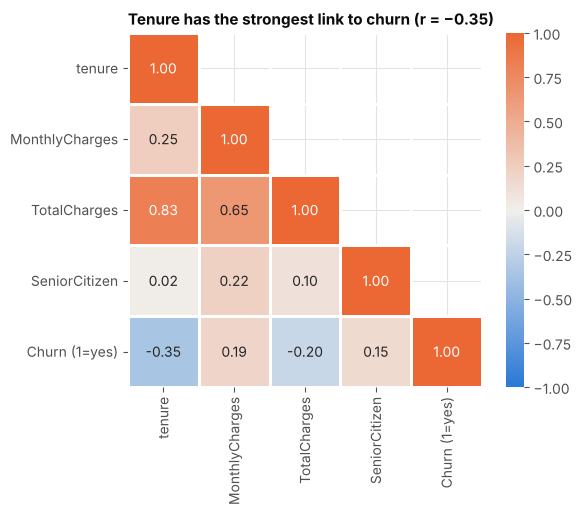

In [7]:
num = df[["tenure", "MonthlyCharges", "TotalCharges_num", "SeniorCitizen", "churn_flag"]].rename(
    columns={"TotalCharges_num": "TotalCharges", "churn_flag": "Churn (1=yes)"})
corr = num.corr()
div = LinearSegmentedColormap.from_list("blue_gray_orange", ["#2a78d6", "#f0efec", "#eb6834"])
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=div, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, ax=ax)
ax.set_title("Tenure has the strongest link to churn (r = −0.35)", loc="left")
fig.savefig(FIG_DIR / "06_correlation_heatmap.png")
plt.show()
print(corr["Churn (1=yes)"].drop("Churn (1=yes)").sort_values().round(2))

**Note for Phase 3/5:** `TotalCharges` is strongly correlated with `tenure` (r ≈ 0.83) because it is roughly tenure × monthly charges. That redundancy is fine for tree models but worth knowing for logistic regression.

## 2.4 Business insights

1. **Contract type is the biggest lever.** Month-to-month customers churn at **42.7%** vs **11.3%** (one-year) and **2.8%** (two-year). They make up **89%** of all churners.
2. **The first year is the danger zone.** Churn is **47.4%** for customers in months 0–12, falling to **9.5%** after four years. Median tenure: churners **10 months**, stayers **38 months**.
3. **Fiber optic customers churn the most (41.9%)** — more than double DSL (19.0%). Combined with month-to-month contracts, churn reaches **54.6%** across 2,128 customers: the single highest-risk segment.
4. **Electronic check payers churn at 45.3%**, roughly 3× customers on automatic bank transfer or credit card (15–17%).
5. **Protective add-ons are associated with retention.** Without OnlineSecurity or TechSupport, churn is ~42%; with them, ~15%.
6. **Price matters:** churners pay a higher median monthly bill (**$79.65 vs $64.43**) but have lower total charges because they leave early.
7. **Demographics matter less, but are visible:** senior citizens churn at **41.7%** vs 23.6%; customers without dependents at 31.3% vs 15.5%. **Gender has no effect** (26.9% vs 26.2%).
8. **Paperless billing customers churn more (33.6% vs 16.3%)** — likely a proxy for digitally active, more price-aware customers rather than a cause.

**Implication for modelling:** contract, tenure, internet service, payment method and the protective add-ons should be the strongest predictors; gender and phone service can likely be dropped or will carry little weight. These are associations, not causes — Phase 6 (SHAP) will test which ones the model actually relies on.

**Possible retention actions to test later:** discounts to move month-to-month customers onto annual contracts, onboarding support in the first 12 months, bundling security/tech-support for fiber customers, and incentives to switch from electronic check to auto-pay.